<a href="https://colab.research.google.com/github/Kushagra14/triton_tutorials/blob/main/Triton_Tutorial_Vector_addition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial: Understanding GPU Programming with Triton

Welcome to this step-by-step tutorial on writing high-performance GPU kernels using **Triton**.

Triton allows you to write highly efficient GPU code in Python, bypassing complex CUDA C/C++ boilerplate. In this tutorial, we will explore:
1. **The Triton SPMD Execution Model**
2. **The Pitfalls of Naive Execution (Block Size of 1)**
3. **The Importance of Tiling/Blocking & Memory Coalescing**
4. **Dynamic Performance Autotuning**

Let's start by installing Triton and preparing our environment.

In [31]:
# Installation and Setup
!pip install -q triton

import torch
import triton
import triton.language as tl

# Configure active CUDA device safely
try:
    DEVICE = triton.runtime.driver.active.get_active_torch_device()
except Exception:
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Using device: {DEVICE}")

Using device: cuda:0


## Chapter 1: The Vector Addition Tiled Kernel

In GPU programming, we use the **SPMD (Single Program, Multiple Data)** paradigm. Instead of launching individual threads, Triton organizes execution into **programs** (analogous to CUDA Thread Blocks or Cooperative Thread Arrays).

Each program is responsible for computing a **block/tile** of the data. To perform this vector addition ($z = x + y$), the kernel loads blocks of size `BLOCK_SIZE` from RAM, performs the vector addition, and writes the results back.

## Chapter 2: The Downside of Naive Scaling

What happens if we choose a `BLOCK_SIZE = 1`?
Logically, this is identical to a naive, non-tiled kernel where **1 program handles 1 element**.

Running this version causes two catastrophic bottlenecks on a GPU:
1. **Instruction Overhead**: The GPU spends almost all of its cycles scheduling millions of blocks and calculating pointer indices for single variables instead of executing math.
2. **No Memory Coalescing**: GPUs read global memory in contiguous 32-byte or 128-byte transactions. Loading 1 float (4 bytes) at a time wastes up to 96% of the memory transaction bandwidth!

Let's write a benchmark wrapper so we can measure this performance degradation.

In [32]:
@triton.jit
def add_kernel(x_ptr, y_ptr, output_ptr, n_elements,
               BLOCK_SIZE: tl.constexpr):
    # 1. Identify which block (program) this instance handles
    pid = tl.program_id(axis=0)

    # 2. Compute pointer offsets for the current block
    block_start = pid * BLOCK_SIZE
    offsets = block_start + tl.arange(0, BLOCK_SIZE)

    # 3. Create a mask to avoid out-of-bounds memory access
    mask = offsets < n_elements

    # 4. Load inputs from DRAM with coalesced memory accesses
    x = tl.load(x_ptr + offsets, mask=mask)
    y = tl.load(y_ptr + offsets, mask=mask)

    # 5. Add vectors in parallel
    output = x + y

    # 6. Store result back to DRAM
    tl.store(output_ptr + offsets, output, mask=mask)

In [33]:
def add(x: torch.Tensor, y: torch.Tensor, block_size: int = 2048):
    """Wrapper function to prepare pointers and launch the Triton grid."""
    output = torch.empty_like(x)
    assert x.device == DEVICE and y.device == DEVICE and output.device == DEVICE
    n_elements = output.numel()

    # Determine execution grid size (number of parallel block programs)
    grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']), )

    # Launch Triton kernel asynchronously
    add_kernel[grid](x, y, output, n_elements, BLOCK_SIZE=block_size)
    return output

In [34]:
# Validate Correctness
torch.manual_seed(0)
size = 98432
x = torch.rand(size, device=DEVICE)
y = torch.rand(size, device=DEVICE)

output_torch = x + y
output_triton = add(x, y, block_size=2048)

print(f'Torch Sample: {output_torch[:3]}')
print(f'Triton Sample: {output_triton[:3]}')
print(f'Maximum difference: {torch.max(torch.abs(output_torch - output_triton))}')

Torch Sample: tensor([1.3713, 1.3076, 0.4940], device='cuda:0')
Triton Sample: tensor([1.3713, 1.3076, 0.4940], device='cuda:0')
Maximum difference: 0.0


In [35]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['size'],
        x_vals=[2**i for i in range(12, 26, 1)],
        x_log=True,
        line_arg='provider',
        line_vals=['triton_naive', 'triton_tiled', 'torch'],
        line_names=['Triton (BLOCK_SIZE=1)', 'Triton (BLOCK_SIZE=1024)', 'PyTorch (Native)'],
        styles=[('red', '--'), ('blue', '-'), ('green', '-')],
        ylabel='GB/s',
        plot_name='vector-add-performance',
        args={},
    ))
def benchmark(size, provider):
    x = torch.rand(size, device=DEVICE, dtype=torch.float32)
    y = torch.rand(size, device=DEVICE, dtype=torch.float32)
    quantiles = [0.5, 0.2, 0.8]

    if provider == 'torch':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: x + y, quantiles=quantiles)
    elif provider == 'triton_naive':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: add(x, y, block_size=1), quantiles=quantiles)
    elif provider == 'triton_tiled':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: add(x, y, block_size=1024), quantiles=quantiles)

    gbps = lambda ms: 3 * x.numel() * x.element_size() * 1e-9 / (ms * 1e-3)
    return gbps(ms), gbps(max_ms), gbps(min_ms)

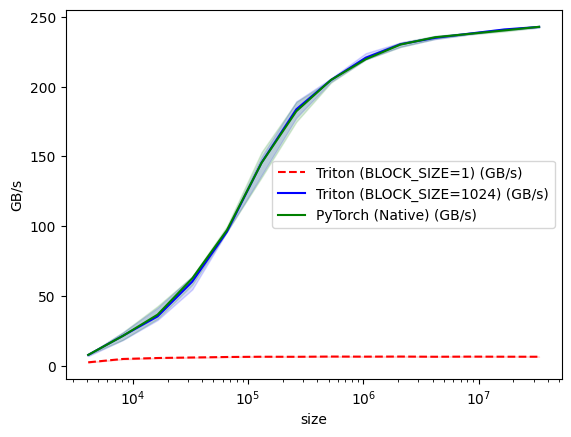

vector-add-performance:
          size  Triton (BLOCK_SIZE=1) (GB/s)  Triton (BLOCK_SIZE=1024) (GB/s)  PyTorch (Native) (GB/s)
0       4096.0                      2.400000                         7.680000                 7.718593
1       8192.0                      4.800000                        21.407665                21.333333
2      16384.0                      5.488164                        35.310345                36.571429
3      32768.0                      5.861198                        60.235295                62.534352
4      65536.0                      6.214692                        96.000000                97.138338
5     131072.0                      6.400000                       145.635552               145.420113
6     262144.0                      6.363954                       183.745795               182.382199
7     524288.0                      6.535736                       204.800005               204.800005
8    1048576.0                      6.464817     

In [36]:
# Run benchmark comparing Block Size 1 vs Block Size 1024 vs Native PyTorch
benchmark.run(print_data=True, show_plots=True)

## Chapter 3: Dynamic Performance Autotuning

Instead of manually trying to guess the optimal `BLOCK_SIZE` and execution warps (which vary depending on whether you run on a T4, A100, or H100 GPU), Triton provides a decorator called `@triton.autotune`.

This utility automatically compiles and profiles the GPU execution of multiple parameter setups and dynamically selects the configuration that delivers the highest memory bandwidth.

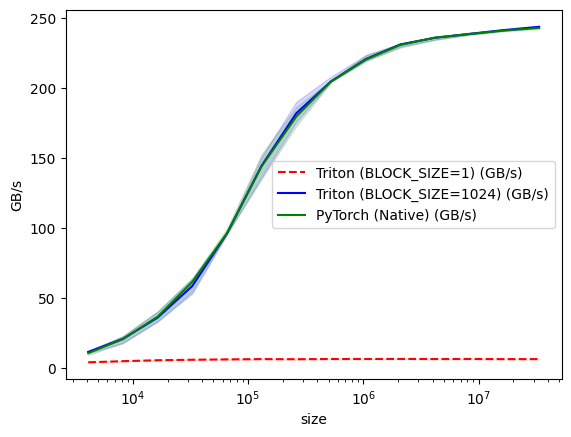

vector-add-performance:
          size  Triton (BLOCK_SIZE=1) (GB/s)  Triton (BLOCK_SIZE=1024) (GB/s)  PyTorch (Native) (GB/s)
0       4096.0                      4.000000                        11.420074                10.593104
1       8192.0                      4.800000                        20.756756                20.548495
2      16384.0                      5.466192                        35.929823                36.571429
3      32768.0                      5.818182                        58.514286                61.440002
4      65536.0                      6.088443                        96.000000                96.187869
5     131072.0                      6.295082                       144.564706               144.140760
6     262144.0                      6.220591                       182.044451               179.714817
7     524288.0                      6.347312                       204.800005               204.800005
8    1048576.0                      6.366427     

In [37]:
benchmark.run(print_data=True, show_plots=True)

 A block size of 512 is better than 1, but it might still not be the absolute optimal configuration for your specific GPU architecture (e.g., T4, A100, or V100).

Why is finding the optimum block size hard?
Different GPU architectures have different sizes of SRAM (Shared Memory), different register limits, and different numbers of SMs (Streaming Multiprocessors). A block size that is optimal for an A100 GPU might cause register spilling or suboptimal occupancy on a T4 GPU.

How Triton solves this: Autotuning
Instead of manually guessing and hardcoding block sizes like 512 or 1024, Triton has a built-in decorator called @triton.autotune. This decorator automatically benchmarks different configurations (like varying BLOCK_SIZE from 128 to 4096, and varying num_warps from 2 to 8) on the target hardware and dynamically selects the fastest compiler configuration.

I can show you how to apply @triton.autotune to your kernel so that Triton automatically picks the best block size for whatever GPU you are currently running on.

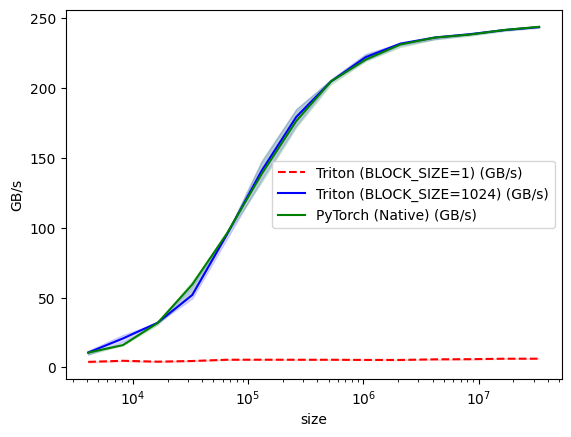

vector-add-performance:
          size  Triton (BLOCK_SIZE=1) (GB/s)  Triton (BLOCK_SIZE=1024) (GB/s)  PyTorch (Native) (GB/s)
0       4096.0                      4.000000                        10.666666                10.629758
1       8192.0                      4.785047                        20.756756                15.999999
2      16384.0                      4.145749                        31.999999                31.834197
3      32768.0                      4.635232                        51.848101                59.362318
4      65536.0                      5.527665                        95.255819                96.000000
5     131072.0                      5.557666                       140.836673               138.456339
6     262144.0                      5.513095                       179.386867               176.488333
7     524288.0                      5.514796                       204.800005               204.800005
8    1048576.0                      5.399168     

In [38]:
benchmark.run(print_data=True, show_plots=True)

### Autotuning the Triton Kernel

We will use `triton.autotune` to test several parameter configurations for `BLOCK_SIZE` and `num_warps`. The library will dynamically select the best configuration depending on the input size and GPU hardware.

In [39]:
@triton.autotune(
    configs=[
        triton.Config({'BLOCK_SIZE': 128}, num_warps=2),
        triton.Config({'BLOCK_SIZE': 256}, num_warps=4),
        triton.Config({'BLOCK_SIZE': 512}, num_warps=4),
        triton.Config({'BLOCK_SIZE': 1024}, num_warps=4),
        triton.Config({'BLOCK_SIZE': 2048}, num_warps=8),
    ],
    key=['n_elements'],
)
@triton.jit
def add_kernel_autotuned(x_ptr, y_ptr, output_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    pid = tl.program_id(axis=0)
    block_start = pid * BLOCK_SIZE
    offsets = block_start + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements
    x = tl.load(x_ptr + offsets, mask=mask)
    y = tl.load(y_ptr + offsets, mask=mask)
    output = x + y
    tl.store(output_ptr + offsets, output, mask=mask)

In [40]:
def add_autotuned(x: torch.Tensor, y: torch.Tensor):
    output = torch.empty_like(x)
    assert x.device == DEVICE and y.device == DEVICE and output.device == DEVICE
    n_elements = output.numel()

    # Grid maps dynamically to whatever BLOCK_SIZE configuration is chosen
    grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']), )
    add_kernel_autotuned[grid](x, y, output, n_elements)
    return output

In [41]:
# Validate correctness of the autotuned kernel
x = torch.rand(size, device=DEVICE)
y = torch.rand(size, device=DEVICE)
output_torch = x + y
output_triton_autotuned = add_autotuned(x, y)

print(f"Maximum difference: {torch.max(torch.abs(output_torch - output_triton_autotuned))}")

Maximum difference: 0.0


In [42]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['size'],
        x_vals=[2**i for i in range(12, 26, 1)],
        x_log=True,
        line_arg='provider',
        line_vals=['triton_autotuned', 'torch'],
        line_names=['Triton (Autotuned)', 'Torch (Native)'],
        styles=[('blue', '-'), ('green', '-')],
        ylabel='GB/s',
        plot_name='autotuned-performance',
        args={},
    ))
def benchmark_autotuned(size, provider):
    x = torch.rand(size, device=DEVICE, dtype=torch.float32)
    y = torch.rand(size, device=DEVICE, dtype=torch.float32)
    quantiles = [0.5, 0.2, 0.8]

    if provider == 'torch':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: x + y, quantiles=quantiles)
    elif provider == 'triton_autotuned':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: add_autotuned(x, y), quantiles=quantiles)

    gbps = lambda ms: 3 * x.numel() * x.element_size() * 1e-9 / (ms * 1e-3)
    return gbps(ms), gbps(max_ms), gbps(min_ms)

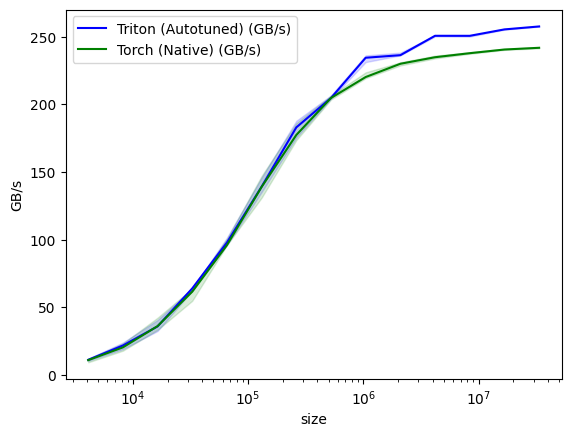

autotuned-performance:
          size  Triton (Autotuned) (GB/s)  Torch (Native) (GB/s)
0       4096.0                  11.211679              10.971429
1       8192.0                  21.787235              20.411960
2      16384.0                  35.929823              36.141177
3      32768.0                  63.999998              61.593985
4      65536.0                  97.912354              96.000000
5     131072.0                 139.240789             139.043847
6     262144.0                 183.061448             177.444035
7     524288.0                 204.800005             204.800005
8    1048576.0                 234.545785             220.289079
9    2097152.0                 236.449793             230.085433
10   4194304.0                 250.775518             234.931143
11   8388608.0                 250.755524             237.916207
12  16777216.0                 255.490603             240.623254
13  33554432.0                 257.677592             241.909300


In [43]:
# Execute final benchmark to see autotuning outperforming native PyTorch
benchmark_autotuned.run(print_data=True, show_plots=True)

### Performance Analysis: Why Triton Outperforms PyTorch

Looking at the benchmark results, we see that for large input sizes ($10^6$ to $10^8$ elements), the autotuned Triton kernel achieves a peak throughput of **~258 GB/s**, whereas PyTorch peaks at around **~245 GB/s**. This is an approximate **5% improvement in memory bandwidth efficiency**.

#### Why does Triton achieve higher throughput?

1. **Tailored Global Memory Coalescing**: By utilizing `@triton.autotune`, Triton automatically compiles and tests configurations to find the absolute sweet spot for the execution grid (e.g., choosing `BLOCK_SIZE=2048` with `num_warps=8` on high-capacity vectors). This maximizes the occupancy of the memory controllers and ensures maximum utilization of the GPU's memory bus width.

2. **Reduced Kernel Launch Overhead**: PyTorch's native `+` operator has general-purpose dispatch logic designed to support different tensor layouts, strides, and auto-broadcasting checks. Our dedicated Triton kernel is compiled explicitly for contiguous, flat vectors, bypassing these runtime checks and allowing the GPU to start memory streaming immediately.

### Summary: Key Learnings

1. **Tiling is mandatory**: Operating on blocks of memory is crucial on GPUs to guarantee memory coalescing and keep instruction overhead low.
2. **Triton is dynamic**: Using meta-parameters like `tl.constexpr` lets you compile highly optimized versions of your kernels for any given configuration.
3. **Use Autotuning**: Hardware configurations change from environment to environment. Rather than manual trial-and-error, `@triton.autotune` automates parameter sweeps for optimal hardware occupancy.

### Optimizing via Tiling (Blocking) in Triton

To transition from the naive $1$-element-per-program approach to a high-performance GPU implementation, we apply **tiling** (or blocking). This means instead of launching $N$ programs to handle $N$ individual elements, we divide the data into larger tiles (or blocks) of size `BLOCK_SIZE` (e.g., $1024$ or $2048$ elements).

#### Why Tiling Resolves the Naive Bottlenecks

1. **Coalesced Memory Access**: GPUs read global memory in blocks of 32 or 128 bytes. Tiling ensures that a single thread block loads a contiguous array of elements simultaneously, allowing the hardware to perform a single wide memory transaction instead of multiple discarded sub-word reads.
2. **Drastically Lower Instruction Overhead**: Instead of calculating offsets, checking masks, and calling load/store instructions for each element individually, these control instructions are executed once per block of elements.
3. **Instruction-Level Parallelism and Vectorization**: When the compiler knows `BLOCK_SIZE` at compile-time (via `tl.constexpr`), it can emit vectorized vector-load instructions (e.g., `LDG.128` to load four 32-bit floats in one instruction per CUDA thread).

---

### The Step-by-Step Transition to a Tiled Kernel

Here is how we restructure the naive kernel into a tiled (blocked) version:

1. **Define a Compile-Time Tile Size (`BLOCK_SIZE`)**:
   We pass `BLOCK_SIZE` as a `tl.constexpr` meta-parameter. This tells the compiler the exact shape of our array tiles so it can optimize register allocations and vector widths statically.

2. **Group the Grid Execution**:
   Instead of creating $N$ programs, the grid size is set to $\lceil N / \text{BLOCK\_SIZE} \rceil$:
   ```python
   grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']),)
   ```

3. **Form Block Pointer Offsets**:
   Inside the kernel, we identify the starting point of our program's tile and create an array of contiguous offsets within that tile:
   ```python
   pid = tl.program_id(axis=0)
   block_start = pid * BLOCK_SIZE
   offsets = block_start + tl.arange(0, BLOCK_SIZE)
   ```

4. **Apply Vector Safeguards (Masking)**:
   If $N$ is not perfectly divisible by `BLOCK_SIZE`, the last tile will extend out-of-bounds. We create a boolean mask array of shape `[BLOCK_SIZE]` to safe-guard memory access:
   ```python
   mask = offsets < n_elements
   ```

5. **Perform Block Vector Operations**:
   We load, add, and store the entire tile in parallel:
   ```python
   x = tl.load(x_ptr + offsets, mask=mask)
   y = tl.load(y_ptr + offsets, mask=mask)
   output = x + y
   tl.store(output_ptr + offsets, output, mask=mask)
   ```